# Filing 200 research abstracts under 508 topics with a decision model

## Filing a paper under one topic

A research catalogue does more than store papers. It files each one under a subject, so that a reader can ask for every paper on stock market forecasting, an editor can find reviewers who work on blockchain security, and a funder can count how many papers on a subject appeared each year. OpenAlex, a free catalogue of research papers, does this with a list of 4,516 topics, arranged in a tree of 26 fields and 252 subfields ([OpenAlex help: Topics](https://help.openalex.org/data/topics/)). Every paper gets one primary topic.

Each filing is a small decision. A paper filed under the wrong topic does not disappear, but it goes missing from the searches and counts that rely on its topic. A reader looking for forecasting papers never sees it; a trend chart is off by one. Filing by hand is slow, so catalogues file automatically, and the useful question is which automatic filings a person still needs to check. Support desks routing tickets to hundreds of queues and shops placing products in category trees face the same problem.

### An illustrative example

This example is simplified. Its measured version is followed through every method in the worked example at the end of section 4.

A paper arrives titled "Stock market prediction using LSTM". Its abstract says it predicts Microsoft's share price from daily opening, highest and lowest prices with an LSTM, a type of neural network built for sequences. Suppose the catalogue had only four topics: stock market forecasting, neural networks, accounting standards and supply chains. A person would read the four, see that the paper is about predicting share prices, and file it under stock market forecasting in a few seconds.

Now give the person 508 topics, each with a paragraph of description. Nobody reads 508 descriptions for every paper. A person narrows the list first. The topics are grouped into 24 subfields, so the natural move is to pick the subfield and then read only the topics inside it.

Here the first step can go wrong. The paper is built around a neural network, so the obvious subfield is Artificial Intelligence, and inside it the obvious topic is "Neural Networks and Applications". But the catalogue keeps "Stock Market Forecasting Methods" in a different subfield, Management Science and Operations Research. A person who opened the Artificial Intelligence shelf will never see the right topic, however carefully they read that shelf. The mistake was made at the first step, and the second step cannot undo it.

A different way to narrow avoids that trap. Instead of choosing a shelf, write down the 25 topics whose descriptions sound most like the paper, from anywhere in the tree, and choose among those. For this paper the short list would hold stock market forecasting near the top, because its description mentions stock price prediction and neural networks in the same paragraph. The cost of this route is a different risk: if the right topic does not sound like the paper, it never makes the short list.

### Letting a model do the filing

A **decision model** is a language model that answers a fixed-choice question instead of writing text. It receives the evidence (here, a paper's title and abstract), a question ("Which research topic is the primary subject of this paper?") and a list of allowed answers, and it returns a probability for every answer. An illustrative reply for the paper above, with three answers on offer, might be 0.90 for stock market forecasting, 0.07 for neural networks and 0.03 for time series forecasting. Nothing has to be parsed out of a sentence, and the answer is always one of the listed topics.

The probability is the second reason to use such a model. A catalogue could file a paper automatically when the model gives its first choice 0.9 or more, and send the rest to a person. That rule only works if the probabilities mean what they say: of all the papers filed at 0.9, about 9 in 10 should be right. A model whose answers match their stated probabilities in this way is called **calibrated**. It is a property to measure, not to assume.

The model cannot simply be handed all 508 topics in one question. The notebook's author reported that the service rejected a question listing all of them, and even where a long list is accepted, sending 508 descriptions with every paper costs about 18 times as many tokens as sending 25 (section 3 explains both). So the list has to be narrowed before the model chooses, and the narrowing step is where the methods differ.

### Ways to narrow the list

This experiment compares three ways of narrowing, each followed by the decision model's choice, and one baseline without the model.

- Shortlist then choose. A text-similarity model, called an embedding model, turns any text into a list of numbers so that texts on similar subjects get similar lists. Comparing these lists ranks all 508 topics almost instantly, at no cost here. The 25 most similar topics go to the decision model, which picks one.
- Subfield first. The decision model picks the subfield, then the topic within it. A second version keeps the three most likely subfields, so a close call at the first step does not decide the answer.
- Tournament. The 508 topics are split into two halves of 254. The model ranks each half, the best 8 of each go to a final of 16, and the model picks the winner. One version lists only the topic names in the first round; the other lists the full descriptions.
- Similarity only. The embedding model's most similar topic is taken as the answer, with no decision model at all. It shows what the decision model adds.

A useful outcome is a method that files the most papers correctly for the money, together with a confidence rule that tells a person which filings to check.

## The question

When an abstract has to be filed under one of 508 research topics, and a decision model cannot be shown all 508 in one question, which way of narrowing the list files the most of 200 abstracts correctly for the money: a 25-topic shortlist by text similarity followed by one question, a subfield first and then a topic, or a two-round tournament? And are the model's probabilities reliable enough to file its confident answers without a person checking them?

A catalogue team, or anyone filing documents against a long label list, needs both answers: the first to choose a design, the second to decide how much of the work still goes to people.

## Study summary

Six methods filed the same 200 abstracts of journal articles, published 2020 to 2024 and drawn at random from OpenAlex, under OpenAlex's 508 topics in computer science, business and decision sciences. Five methods ask OpenAI Decisions, a decision model reached through the OpenRouter service; the sixth uses text similarity alone. The right answer for each abstract is the topic OpenAlex's own classifier gave it.

- Shortlist then choose filed 179 of 200 abstracts under OpenAlex's topic (89.5%, 95% interval 85% to 94%) for \$0.29 per 1,000 abstracts, with one model call each. Its 25-topic shortlist held the right topic for 191 of the 200; similarity alone, taking the most similar topic, got 127 right (63.5%).
- The other model-based methods filed 153 to 172 correctly. Subfield first got 153 (76.5%), because its first step sent 39 abstracts to the wrong subfield. Keeping the top three subfields raised that to 171 (85.5%) at \$1.56 per 1,000, and the tournament with descriptions reached 172 (86.0%) at \$5.25. Shortlist then choose's lead over these two could be chance (it alone was right on 20 and 16 abstracts, they alone on 12 and 9), but it costs about a fifth and an eighteenth as much.
- 5 of the 1,000 model-based runs ended in a refusal, a reply that cannot be scored; they count as wrong. On readable replies the order of the methods does not change (shortlist then choose: 179 of 199).
- Accepting answers with a confidence of 0.9 or more would file 173 of 200 abstracts automatically, 162 of them under OpenAlex's topic (93.6%), and send 27 to a person. The probabilities run high: answers in that band averaged 0.99 but were right 93.6% of the time. Answers given probability 1 were right 122 of 123 times; those between 0.90 and 0.98 only 22 of 31.

In the original situation: a team filing papers could let shortlist then choose file about 86 in every 100 automatically and check the rest; about 1 in 16 of the automatic filings would differ from OpenAlex's topic, and several of those differences are readings a person could defend.

The main caveat is that the right answers are OpenAlex's automatic labels, not a person's, and that the papers and their labels were public before the model was released, so the model may have seen them. The accuracy is an upper bound for new papers, and with 200 abstracts, gaps of a few points between the better methods could be chance.

## Contents
1. [Setup and models](#1.-Setup-and-models)
2. [Data](#2.-Data)
3. [Why the topics must be narrowed first](#3.-Why-the-topics-must-be-narrowed-first)
4. [Methods](#4.-Methods)
5. [Results](#5.-Results)
6. [Error analysis](#6.-Error-analysis)
7. [Spend and how to reproduce](#7.-Spend-and-how-to-reproduce)
8. [What the evidence supports](#8.-What-the-evidence-supports)
9. [Limitations](#9.-Limitations)
10. [Future work and further reading](#10.-Future-work-and-further-reading)

## Workflow

The whole experiment, from data to results, with the counts from this run. One abstract travels through it like this: its title and abstract are turned into a list of numbers by the embedding model; similarity only takes the closest topic; shortlist then choose sends the 25 closest topics to OpenAI Decisions in one call; the tournament and subfield first each make two calls in sequence; each method's first choice is compared with OpenAlex's topic, and its confidence is kept for the checks in section 5.3.

```mermaid
flowchart TD
    topics["OpenAlex topics in 3 fields<br/>508 topics in 24 subfields<br/>name, description, keywords"]
    works["OpenAlex works<br/>600 random English journal articles, 2020-2024"]
    filt["Keep topic score ≥ 0.9 and abstract ≥ 80 words: 332<br/>random sample of 200 abstracts, 131 distinct topics"]
    emb["Embedding model (free, via OpenRouter)<br/>708 vectors: 508 topic texts + 200 abstracts"]
    A["A. Similarity only<br/>no model call"]
    D["D. Shortlist then choose<br/>200 Decisions calls, 1 refused"]
    B["B1, B2. Tournament<br/>797 distinct Decisions calls, 2 refused"]
    C["C1, C2. Subfield first<br/>598 distinct Decisions calls, 1 refused<br/>(first step shared by both)"]
    score["Score 6 methods x 200 abstracts against OpenAlex's topic<br/>1,000 model-based runs: 995 answered, 5 refused"]
    res["Accuracy, cost per 1,000 abstracts, seconds per abstract,<br/>confidence checks, error cases"]
    topics --> emb
    works --> filt --> emb
    emb --> A
    emb --> D
    topics --> B
    topics --> C
    filt --> B
    filt --> C
    A --> score
    B --> score
    C --> score
    D --> score
    score --> res
```

The run used 1,595 distinct Decisions calls. The two subfield-first versions share their identical first call (and one refusal), and the two tournaments happened to share one final, so 5 refused runs come from 4 refused calls.

## 1. Setup and models

The next cell loads the libraries, sets the folder paths and fixes the settings every later cell uses: the two endpoints, the model names, the three OpenAlex fields, the sample size (`N_DOCS = 200`), the random seed (42) and the number of abstracts processed in parallel (8). The notebook runs offline. Every model response is cached in `data/`, so a re-run replays from disk and needs no key; `OPENROUTER_API_KEY` is needed only for a request that is not in the cache. Dependencies are in `requirements.txt` at the repository root.

Two models are used:

| Model | Pinned version | Provider and how called | Size and precision | Settings | Why included |
|---|---|---|---|---|---|
| OpenAI Decisions | `openai/gpt-6-luna-decisions-20261006`, returned in the `model` field of all 1,791 answered responses in `data/decisions_cache.jsonl`; requested as the undated `openai/gpt-6-luna-decisions` | OpenAI, through OpenRouter's Decisions endpoint (an HTTP request; the model has no command-line tool) | Not published | No sampling settings; each request carries only the evidence and the questions | The decision model under test: it returns a probability for every listed topic |
| Llama Nemotron Embed VL 1B v2 (the embedding model) | `nvidia/llama-nemotron-embed-vl-1b-v2:free`; no dated version recorded | NVIDIA, through OpenRouter's free embeddings endpoint | About 1B parameters (from the name); precision not recorded | 512-number vectors, scaled to length 1 | Free; builds the shortlist for shortlist then choose and is the similarity-only baseline |

`data/` records no training cutoff or release date for either model. The dated suffix shows the Decisions version is from 6 October 2026 or later. The free embedding endpoint allows 1,000 requests a day per key and may log its inputs, which is acceptable for these public abstracts but not for private documents. The Decisions endpoint has no free version; its spend is counted in section 7.

In [1]:
import hashlib, json, os, threading, time
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

ROOT = Path.cwd()  # this notebook's folder
DATA = ROOT / "data"
DATA.mkdir(parents=True, exist_ok=True)

DECISIONS_URL = "https://openrouter.ai/api/alpha/decisions"
EMBED_URL = "https://openrouter.ai/api/v1/embeddings"
DECISIONS_MODEL = "openai/gpt-6-luna-decisions"
EMBED_MODEL = "nvidia/llama-nemotron-embed-vl-1b-v2:free"  # free
FIELDS = {"17": "Computer Science", "14": "Business, Management and Accounting", "18": "Decision Sciences"}
N_DOCS, SEED, WORKERS = 200, 42, 8

HEADERS = {"Authorization": f"Bearer {os.environ.get('OPENROUTER_API_KEY', '')}"}  # only used on a cache miss
pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

### 1.1 Helpers

The next cell defines the small tools the experiment needs. One sends a request and waits and retries when the service is busy or briefly failing. One saves every Decisions response to `data/decisions_cache.jsonl`, filed under a fingerprint of the full request, so that the same request is never paid for twice and a re-run reads the saved answer. One makes a single Decisions call, and one returns the saved embedding vectors for a list of texts.

Refusals get special handling. When the service answers with an error saying the model refused the question, the refusal is saved like an answer and is not retried. The method then records no label and a confidence of 0 for that abstract. This keeps refusals, which are replies the program cannot score, apart from answers that were read and found wrong.

In [2]:
class Refused(Exception):
    """The model declined to answer a question (HTTP 502 'refused to answer'); not worth retrying."""


def post(url, payload, tries=8):
    """POST with exponential backoff on 429/5xx; raises on any other error (e.g. 400 validation)."""
    if not os.environ.get("OPENROUTER_API_KEY"):
        raise RuntimeError(f"Not in the cache and OPENROUTER_API_KEY is not set ({url})")
    for attempt in range(tries):
        r = requests.post(url, json=payload, headers=HEADERS, timeout=180)
        if r.status_code == 200:
            return r.json()
        if r.status_code == 502 and "refused" in r.text:
            raise Refused(r.text[:200])
        if r.status_code in (429, 500, 502, 503, 504) and attempt < tries - 1:
            time.sleep(min(60, 5 * 2**attempt) if r.status_code == 429 else 2**attempt)  # free models rate-limit harder
            continue
        raise RuntimeError(f"HTTP {r.status_code}: {r.text[:400]}")


class JsonlCache:
    """Append-only on-disk cache for API responses, keyed by the request payload."""

    def __init__(self, path):
        self.path, self.lock, self.data = path, threading.Lock(), {}
        if path.exists():
            for line in path.read_text(encoding="utf-8").splitlines():
                row = json.loads(line)
                self.data[row["key"]] = row["value"]

    def get(self, payload, fn):
        key = hashlib.sha256(json.dumps(payload, sort_keys=True).encode()).hexdigest()
        if key not in self.data:
            value = fn(payload)
            with self.lock:
                self.data[key] = value
                with self.path.open("a", encoding="utf-8") as f:
                    f.write(json.dumps({"key": key, "value": value}) + "\n")
        return self.data[key]


decision_cache = JsonlCache(DATA / "decisions_cache.jsonl")


def decide(state, questions):
    """One Decisions API call. Returns {'answers', 'usage', 'model', 'latency_s'}."""

    def call(payload):
        t0 = time.perf_counter()
        try:
            out = post(DECISIONS_URL, payload)
        except Refused as e:
            return {"refused": str(e)}
        return {"answers": out["answers"], "usage": out["usage"], "model": out["model"],
                "latency_s": time.perf_counter() - t0}

    result = decision_cache.get({"model": DECISIONS_MODEL, "state": state, "questions": questions}, call)
    if "refused" in result:
        raise Refused(result["refused"])
    return result


EMB_PATH = DATA / "embeddings_cache.npz"
if EMB_PATH.exists():
    with np.load(EMB_PATH) as z:  # plain arrays, no pickle
        emb_cache = dict(zip(z["keys"].tolist(), z["vectors"]))
else:
    emb_cache = {}


def save_emb_cache():
    keys = list(emb_cache)
    np.savez(EMB_PATH, keys=np.array(keys), vectors=np.stack([emb_cache[k] for k in keys]).astype(np.float32))


def embed(texts, batch=256):
    """L2-normalised embeddings (512-d), cached per text."""
    key = lambda t: hashlib.sha1(f"{EMBED_MODEL}|{t}".encode()).hexdigest()
    missing = list(dict.fromkeys(t for t in texts if key(t) not in emb_cache))
    for i in range(0, len(missing), batch):
        part = missing[i : i + batch]
        inputs = [t if t.strip() else "(blank)" for t in part]  # the free model rejects empty strings
        out = post(EMBED_URL, {"model": EMBED_MODEL, "input": inputs, "dimensions": 512, "encoding_format": "float"})
        for t, d in zip(part, sorted(out["data"], key=lambda d: d["index"])):
            emb_cache[key(t)] = np.asarray(d["embedding"], dtype=np.float32)
    if missing:
        save_emb_cache()
    X = np.stack([emb_cache[key(t)] for t in texts])
    return X / np.linalg.norm(X, axis=1, keepdims=True)


def pmap(fn, items):
    """Parallel map; a refusal becomes an abstention (no label, confidence 0) instead of a crash."""

    def safe(x):
        try:
            return fn(x)
        except Refused:
            return {"top": ["<refused>"], "conf": 0.0, "calls": [], "refused": True}

    with ThreadPoolExecutor(WORKERS) as ex:
        return list(ex.map(safe, items))

## 2. Data
### 2.1 The 508 topics

The next cell downloads, once, every OpenAlex topic in three fields (Computer Science; Business, Management and Accounting; Decision Sciences) into `data/openalex_topics.json`, and keeps each topic's name, description, first six keywords, subfield and field. These are the labels. Every method compares an abstract with a topic text built from the name, the description and the keywords. The output should show 508 topics in 24 subfields, and four sample topics with the start of their descriptions.

In [3]:
OA = "https://api.openalex.org"
topics_path = DATA / "openalex_topics.json"
if not topics_path.exists():
    rows = []
    for page in (1, 2, 3):
        r = requests.get(f"{OA}/topics", timeout=60, params={
            "filter": "field.id:" + "|".join(FIELDS), "per-page": 200, "page": page,
            "select": "id,display_name,description,keywords,subfield,field"})
        r.raise_for_status()
        rows += r.json()["results"]
    topics_path.write_text(json.dumps(rows, indent=1), encoding="utf-8")

topics = pd.DataFrame([{
    "topic": t["display_name"], "description": t["description"],
    "keywords": ", ".join(k["display_name"] for k in t["keywords"][:6]),
    "subfield": t["subfield"]["display_name"], "field": t["field"]["display_name"],
} for t in json.loads(topics_path.read_text(encoding="utf-8"))])
assert topics.topic.is_unique and topics.subfield.nunique() == 24
print(f"{len(topics)} labels | {topics.subfield.nunique()} subfields | {topics.field.nunique()} fields")
topics.sample(4, random_state=1)[["topic", "subfield", "description"]]

508 labels | 24 subfields | 3 fields


,topic,subfield,description
444,Operations Management Techniques,Management Science and Operations Research,This cluster of papers revolves around the Theory of Constraints (TOC) and its applica...
344,"Chaos, Complexity, and Education",Computational Theory and Mathematics,"This cluster of papers explores the interdisciplinary field of complexity theory, focu..."
47,Innovation and Knowledge Management,Strategy and Management,"This cluster of papers revolves around the topics of knowledge management, organizatio..."
67,Consumer Behavior in Brand Consumption and Identification,Marketing,This cluster of papers explores various aspects of consumer behavior in relation to br...


The four sample rows show what a topic looks like: a short name ("Operations Management Techniques"), its subfield, and a description that begins "This cluster of papers..." and summarises the papers OpenAlex grouped under it. The full topic text sent to the model adds keywords; for Stock Market Forecasting Methods it runs to 538 characters.

The next chart counts topics per subfield, coloured by field (blue Computer Science, red Business, Management and Accounting, green Decision Sciences). Look at how uneven the subfields are, because subfield first has to choose one before it sees any topics.

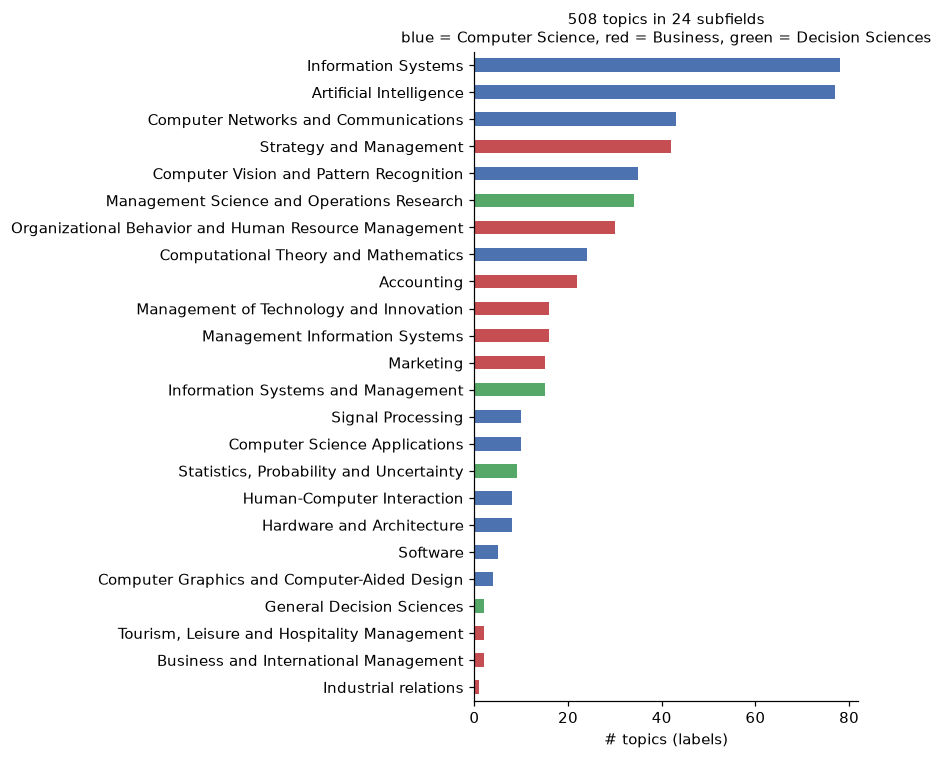

In [4]:
counts = topics.groupby(["field", "subfield"]).size().sort_values()
ax = counts.plot.barh(figsize=(8, 7), color=[{"Computer Science": "#4C72B0", "Decision Sciences": "#55A868"}.get(f, "#C44E52") for f, _ in counts.index])
ax.set_yticklabels([s for _, s in counts.index]); ax.set_ylabel(""); ax.set_xlabel("# topics (labels)")
ax.set_title("508 topics in 24 subfields\nblue = Computer Science, red = Business, green = Decision Sciences", fontsize=10)
plt.tight_layout(); plt.show()

Computer Science holds 302 of the 508 topics, Business, Management and Accounting 146 and Decision Sciences 60. Information Systems has 78 topics and Artificial Intelligence 77, while Industrial relations has one and three other subfields have two. A method that picks the subfield first therefore faces anything from 1 to 78 topics in its second step. The large subfields also attract wrong first steps: of the 39 abstracts that subfield first with one subfield sent to the wrong subfield, 14 went to Artificial Intelligence (section 5.2).

### 2.2 The 200 abstracts

The next cell downloads, once, a random sample of 600 English journal articles published 2020 to 2024 whose OpenAlex primary topic is in one of the three fields (sampled with seed 42, saved to `data/openalex_works.jsonl`). It rebuilds each abstract from OpenAlex's word-position format and keeps two kinds of work:

- OpenAlex gives each primary topic a score, its classifier's probability that the topic is right. Only works scored 0.9 or more are kept, which removes the most ambiguous cases.
- The abstract must have at least 80 words, so there is enough text to classify.

From the works that pass, it draws 200 at random. Each model sees the title and abstract, cut at 3,000 characters.

The right answer is OpenAlex's primary topic, a silver label: assigned by a program and checked by no one for this experiment. OpenAlex's help page (checked 28 October 2026) says its classifier was replaced in October 2026; the old one read title, abstract, citations and journal, the new one title, abstract and source name. The download date of the works file is not recorded, so which one labelled these abstracts is not known. Subfield accuracy is less sensitive to these labels than exact-topic accuracy, because neighbouring topics usually share a subfield.

OpenAlex releases its data under a CC0 public-domain licence ([OpenAlex help: Pricing](https://help.openalex.org/hc/en-us/articles/24397762024087-Pricing)), so the topics and works are saved in `data/`. This notebook was built before the repository's rule that test data must be newer than the models. Every paper was published by 2024, and OpenAlex's topics, descriptions and topic assignments were public before OpenAI Decisions was released, so the model may have seen these papers with their topics. Its accuracy here is therefore an upper bound for papers it has never seen.

In [5]:
works_path = DATA / "openalex_works.jsonl"
if not works_path.exists():
    params = {"filter": "primary_topic.field.id:17|14|18,has_abstract:true,type:article,language:en,"
                        "publication_year:2020-2024",
              "sample": 600, "seed": SEED, "per-page": 200,
              "select": "id,title,publication_year,primary_topic,abstract_inverted_index"}
    rows = []
    for page in (1, 2, 3):
        r = requests.get(f"{OA}/works", params={**params, "page": page}, timeout=120)
        r.raise_for_status()
        rows += r.json()["results"]
    works_path.write_text("\n".join(json.dumps(r) for r in rows), encoding="utf-8")


def abstract_text(inverted):
    pos = {i: w for w, idxs in (inverted or {}).items() for i in idxs}
    return " ".join(pos[i] for i in sorted(pos))


works = pd.DataFrame([{
    "work_id": w["id"].rsplit("/", 1)[-1], "title": (w["title"] or "").strip(),
    "abstract": abstract_text(w["abstract_inverted_index"]),
    "topic": w["primary_topic"]["display_name"], "topic_score": w["primary_topic"]["score"],
} for w in map(json.loads, works_path.read_text(encoding="utf-8").splitlines())])
works = works[works.topic.isin(topics.topic)].drop_duplicates("work_id").drop_duplicates("title")
pool = works[(works.topic_score >= 0.9) & (works.abstract.str.split().str.len() >= 80)]
docs = pool.sample(N_DOCS, random_state=SEED).reset_index(drop=True)
docs = docs.merge(topics[["topic", "subfield", "field"]], on="topic", how="left")
docs["text"] = (docs.title + "\n\n" + docs.abstract).str.slice(0, 3000)
print(f"fetched {len(works)} → confident pool {len(pool)} → sample {len(docs)} docs "
      f"covering {docs.topic.nunique()} distinct gold topics")
docs[["title", "topic", "subfield"]].head()

fetched 600 → confident pool 332 → sample 200 docs covering 131 distinct gold topics


,title,topic,subfield
0,The axiological background of the phenomenon of leadership,Leadership and Management in Organizations,Strategy and Management
1,Website Based Academic Information System Design Using Extreme Programming Method,Engineering and Information Technology,Software
2,Youth perception towards entrepreneurial ecosystem in bangladesh: A deep diving invest...,Entrepreneurship Studies and Influences,Management of Technology and Innovation
3,SoK: Realistic adversarial attacks and defenses for intelligent network intrusion dete...,Adversarial Robustness in Machine Learning,Artificial Intelligence
4,The Jordan Canonical Form of a Product of Elementary S -unitary Matrices,Matrix Theory and Algorithms,Computational Theory and Mathematics


All 600 sampled works have a topic among the 508 and none are duplicates. The two filters leave 332, and the 200 drawn from those cover 131 distinct topics. The first five rows show the range: a paper on leadership, one on an academic information system, one on entrepreneurship in Bangladesh, one on attacks against intrusion detection, and one on matrix theory (the Jordan canonical form paper, which returns in the error analysis).

The next chart has three panels: abstracts per field, how many topics have 1, 2, 3 or more abstracts, and the distribution of abstract lengths in words.

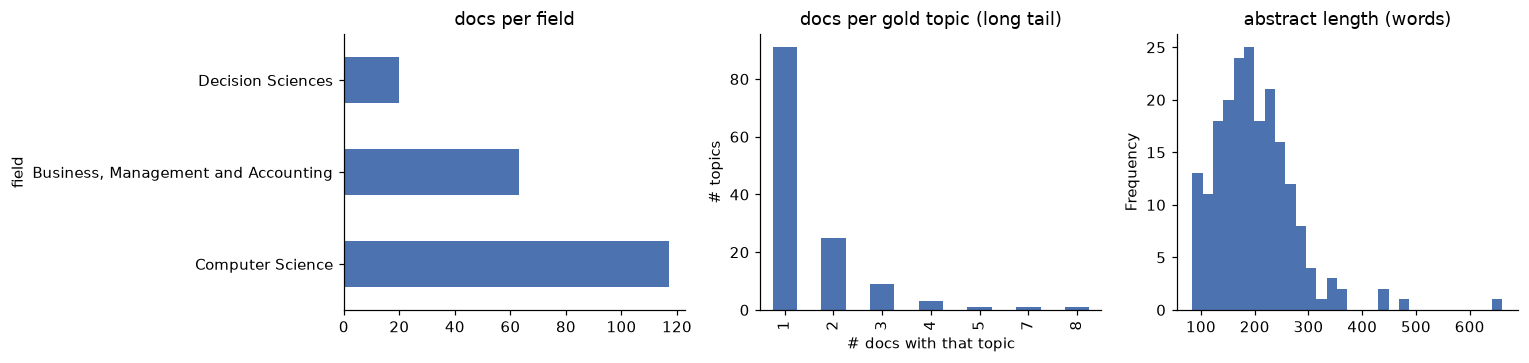

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.4))
docs.field.value_counts().plot.barh(ax=axes[0], color="#4C72B0", title="docs per field")
docs.topic.value_counts().value_counts().sort_index().plot.bar(ax=axes[1], color="#4C72B0", title="docs per gold topic (long tail)")
axes[1].set_xlabel("# docs with that topic"); axes[1].set_ylabel("# topics")
docs.abstract.str.split().str.len().plot.hist(ax=axes[2], bins=30, color="#4C72B0", title="abstract length (words)")
plt.tight_layout(); plt.show()

By field, 117 abstracts are in Computer Science, 63 in Business, Management and Accounting and 20 in Decision Sciences, close to the share of topics in each field. The middle panel shows a long tail: 91 of the 131 topics appear once, 25 twice and 15 three times or more, so the score is spread over many topics rather than decided by a few frequent ones. Abstracts run from 84 to 661 words, with a median of 192; 3 of the 200 texts were shortened by the 3,000-character cut. By year the sample holds 22 abstracts from 2020, 38 from 2021, 46 from 2022, 49 from 2023 and 45 from 2024.

## 3. Why the topics must be narrowed first

The simplest design would be one `choice` question with all 508 topic texts as its options. The next cell defines the question wording, the topic texts and the lookups from topic to subfield and field that later cells use, and then sends that 508-option question for the first abstract.

In [7]:
INSTR = "Which research topic is the primary subject of this paper? Choose the single best-matching topic."
DESC = dict(zip(topics.topic, topics.topic + ". " + topics.description + " Keywords: " + topics.keywords + "."))
SUB_OF = dict(zip(topics.topic, topics.subfield)) | {"<refused>": None}
FIELD_OF = dict(zip(topics.topic, topics.field)) | {"<refused>": None}

try:
    decide(docs.text[0], {"topic": {"type": "choice", "instructions": INSTR, "criteria": DESC}})
except RuntimeError as e:
    print(str(e)[:330])

Not in the cache and OPENROUTER_API_KEY is not set (https://openrouter.ai/api/alpha/decisions)


The output is not the service's reply. The cache stores only answers and refusals, and this request was neither, so a replay without an API key stops at the cache and prints the message above. The notebook's author reported that the service rejected the 508-option question and that one question accepts at most 255 options, and every design below keeps its questions at 254 options or fewer. The rejection itself was not saved, so this repository holds no direct evidence for the limit. Neither OpenAI's guide nor OpenRouter's reference, checked on 28 October 2026, states a limit on options per question; OpenAI's guide allows 1 to 400 questions per request.

Cost is the second reason to narrow, and it is measured. Each request is billed by its input tokens at \$0.10 per million, and output tokens are always 0 (fields `usage.cost`, `usage.input_tokens` and `usage.output_tokens` in `data/decisions_cache.jsonl`). Several questions about the same evidence can share one request. The tournament's first round below, which lists all 508 descriptions across two questions in one request, used 50,985 input tokens per abstract on average; a 25-topic question used 2,890.

## 4. Methods

Every method returns, for each abstract, a ranked list of topics, a confidence (the probability given to its first choice) and the raw responses, which the results use for cost and time.

| Letter | Method | What it does | Decision model calls per abstract |
|---|---|---|---|
| A | Similarity only | Ranks the 508 topics by similarity to the abstract and takes the first | 0 |
| B1 | Tournament with names | Round 1: two questions in one call, each over 254 topic names; the top 8 of each go to a final over 16 full descriptions | 2 |
| B2 | Tournament with descriptions | As B1, but round 1 lists full descriptions (about 6.6 times the tokens) | 2 |
| C1 | Subfield first, top 1 | Picks one of 24 subfields, then a topic among that subfield's topics (up to 78) | 2 |
| C2 | Subfield first, top 3 | Keeps the three most likely subfields and picks among their pooled topics (up to 198) | 2 |
| D | Shortlist then choose | Keeps the 25 most similar topics and asks one question over them | 1 |

The code and the charts label the methods "A. embedding nearest-label", "B1. tournament (names → final)", "B2. tournament (descriptions → final)", "C1. cascade (beam=1)", "C2. cascade (beam=3)" and "D. embed top-25 → decide". The text uses the plain names.

Every method asks the same question ("Which research topic is the primary subject of this paper? Choose the single best-matching topic."), and every final question shows full topic descriptions, so the methods differ only in how they narrow. Similarity only is the simplest reasonable alternative: it shows what the decision model adds over the cheap ranking it starts from.

Model calls per abstract for the three model-based designs. Each box is one call to OpenAI Decisions through OpenRouter, or one lookup in the embedding model. Arrows show what one call passes to the next. The calls for one abstract run in sequence, and 8 abstracts run in parallel.

```mermaid
flowchart LR
    doc["Abstract<br/>title + abstract, up to 3,000 characters"]
    subgraph B ["Tournament (B1: names in round 1, B2: descriptions)"]
        b1["Decisions call 1<br/>2 questions in one call, 254 topics each<br/>returns a probability per topic"]
        b2["Decisions call 2<br/>1 question over 16 finalists<br/>full descriptions"]
        b1 -->|"top 8 of each half"| b2
    end
    subgraph C ["Subfield first (C1: top 1, C2: top 3)"]
        c1["Decisions call 1<br/>1 question over 24 subfields"]
        c2["Decisions call 2<br/>topics of the kept subfields<br/>up to 78 (C1) or 198 (C2)"]
        c1 -->|"top 1 or top 3 subfields"| c2
    end
    subgraph D ["Shortlist then choose"]
        d1["Embedding model<br/>similarity to 508 topic texts"]
        d2["Decisions call<br/>1 question over the top 25 topics"]
        d1 -->|"top 25 topics"| d2
    end
    pred["First choice, ranked list, confidence"]
    doc --> b1
    doc --> c1
    doc --> d1
    b2 --> pred
    c2 --> pred
    d2 --> pred
```

### A. Similarity only (no decision model)

The next cell turns each of the 508 topic texts and each of the 200 abstracts into a vector with the embedding model, ranks the topics for each abstract by cosine similarity (how closely two vectors point the same way), and takes the first as the answer. It also turns the similarities into a pseudo-confidence with a softmax; this is not a probability from any model, so similarity only is left out of the confidence checks in section 5.3.

The same ranking supplies the shortlist for method D, which can only pick a topic that is on its list. The chart below shows the **shortlist recall**: for each length K on the horizontal axis, the share of the 200 abstracts whose right topic is among the K most similar topics. K = 1 is the accuracy of similarity only. Look at how fast the curve rises and where it flattens.

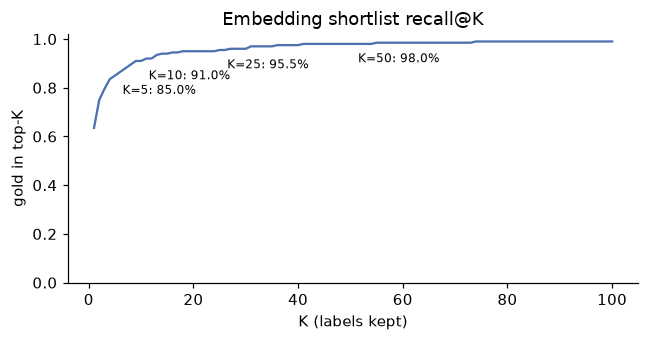

In [8]:
L = embed([DESC[t] for t in topics.topic])
D = embed(docs.text.tolist())
sim = D @ L.T
emb_rank = np.argsort(-sim, axis=1)
labels = topics.topic.to_numpy()
gold_idx = np.array([np.flatnonzero(labels == t)[0] for t in docs.topic])


def softmax(x, t=0.02):
    z = np.exp((x - x.max()) / t)
    return z / z.sum()


preds = {"A. embedding nearest-label": [
    {"top": list(labels[emb_rank[i, :5]]), "conf": float(softmax(sim[i])[emb_rank[i, 0]]), "calls": []}
    for i in range(len(docs))]}

# shortlist recall: how often is the gold label within the embedding top-K? (this drives method D)
ranks = np.array([np.flatnonzero(emb_rank[i] == gold_idx[i])[0] for i in range(len(docs))])
ks = np.arange(1, 101)
plt.figure(figsize=(6, 3.2))
plt.plot(ks, [(ranks < k).mean() for k in ks], color="#4C72B0")
for k in (5, 10, 25, 50):
    plt.annotate(f"K={k}: {(ranks < k).mean():.1%}", (k, (ranks < k).mean()), textcoords="offset points", xytext=(5, -12), fontsize=8)
plt.xlabel("K (labels kept)"); plt.ylabel("gold in top-K"); plt.title("Embedding shortlist recall@K"); plt.ylim(0, 1.02)
plt.tight_layout(); plt.show()

Taking the most similar topic is right for 127 of 200 abstracts (63.5%). Keeping 5 topics holds the right one for 170 (85.0%), 10 for 182 (91.0%), 25 for 191 (95.5%), 50 for 196 (98.0%) and 100 for 198 (99.0%). The embedding model is therefore much better at narrowing than at choosing: the right topic is usually near the top, but often not first.

The shortlist length of 25 was chosen from this curve: it keeps the right topic for 95.5% of abstracts while each question stays short (about 2,900 input tokens). Doubling it to 50 would add 5 abstracts. The 9 abstracts whose topic falls outside the 25 are a fixed loss for method D, whatever the decision model does with them.

### B. Tournament: two 254-topic questions in one call, then a final

Round 1 splits the 508 topics into two fixed random halves and asks one `choice` question per half. Both questions go in the **same call**, so the abstract is sent and billed once. The 8 most probable topics from each half go to a 16-topic final, which always shows full descriptions. Two versions of round 1 are compared:

- names: the options are just the topic names, which is cheap;
- descriptions: the options are the full topic texts, about 6.6 times the input tokens of the names version.

The comparison shows whether the model needs descriptions to keep the right topic among the finalists.

In [9]:
groups = np.array_split(np.random.default_rng(SEED).permutation(labels), 2)


def ranked(probs, n=5):
    return sorted(probs, key=probs.get, reverse=True)[:n]


def tournament(text, first_round="names", k=8):
    criteria = (lambda t: t) if first_round == "names" else DESC.get
    r1 = decide(text, {f"group_{g}": {"type": "choice", "instructions": INSTR,
                                      "criteria": {t: criteria(t) for t in grp}}
                       for g, grp in enumerate(groups)})
    finalists = [t for g in range(len(groups)) for t in ranked(r1["answers"][f"group_{g}"]["probabilities"], k)]
    r2 = decide(text, {"topic": {"type": "choice", "instructions": INSTR,
                                 "criteria": {t: DESC[t] for t in finalists}}})
    p = r2["answers"]["topic"]["probabilities"]
    return {"top": ranked(p), "conf": max(p.values()), "calls": [r1, r2]}


preds["B1. tournament (names → final)"] = pmap(lambda x: tournament(x, "names"), docs.text)
preds["B2. tournament (descriptions → final)"] = pmap(lambda x: tournament(x, "descriptions"), docs.text)

### C. Subfield first

Step 1 is a `choice` question over the 24 subfields. Each subfield is described by its field and the names of its topics, for example "Decision Sciences › Management Science and Operations Research. Topics include: Construction Project Management and Performance; Multi-Criteria Decision Making; ...". Step 2 is a `choice` question over the topics of the chosen subfield (up to 78).

The top-1 version keeps only the most probable subfield. The top-3 version pools the topics of the three most probable subfields (up to 198 options), so a near tie in step 1 does not decide the answer. The confidence multiplies the probability of the kept subfields by the probability of the chosen topic.

In [10]:
SUB_DESC = {sf: f"{g.field.iloc[0]} › {sf}. Topics include: " + "; ".join(g.topic) + "."
            for sf, g in topics.groupby("subfield")}


def cascade(text, beam=1):
    r1 = decide(text, {"subfield": {"type": "choice", "instructions":
                                    "Which research area (subfield) is the primary subject of this paper?",
                                    "criteria": SUB_DESC}})
    psub = r1["answers"]["subfield"]["probabilities"]
    keep = ranked(psub, beam)
    cand = topics.topic[topics.subfield.isin(keep)].tolist()
    mass = sum(psub[s] for s in keep)
    if len(cand) == 1:  # e.g. "Industrial relations" has a single topic
        return {"top": cand, "conf": mass, "calls": [r1]}
    r2 = decide(text, {"topic": {"type": "choice", "instructions": INSTR, "criteria": {t: DESC[t] for t in cand}}})
    p = r2["answers"]["topic"]["probabilities"]
    return {"top": ranked(p), "conf": mass * max(p.values()), "calls": [r1, r2]}


preds["C1. cascade (beam=1)"] = pmap(lambda x: cascade(x, 1), docs.text)
preds["C2. cascade (beam=3)"] = pmap(lambda x: cascade(x, 3), docs.text)

### D. Shortlist then choose

Keep the 25 topics most similar to the abstract by the embedding ranking above and ask OpenAI Decisions one question over their full texts. It is one call per abstract, and the question lists 25 of the 508 topics.

In [11]:
K = 25


def shortlist(i):
    cand = labels[emb_rank[i, :K]]
    r = decide(docs.text[i], {"topic": {"type": "choice", "instructions": INSTR, "criteria": {t: DESC[t] for t in cand}}})
    p = r["answers"]["topic"]["probabilities"]
    return {"top": ranked(p), "conf": max(p.values()), "calls": [r]}


preds[f"D. embed top-{K} → decide"] = pmap(shortlist, range(len(docs)))

### Worked example: one abstract through every method

This is the measured version of the opening example: OpenAlex work W4383504851, "STOCK MARKET PREDICTION USING LSTM" (2020, 137 words). OpenAlex files it under Stock Market Forecasting Methods, in the subfield Management Science and Operations Research, with a score of 1.0.

Shortlist then choose first ranks the 508 topic texts by similarity. Stock Market Forecasting Methods comes first, ahead of Sentiment Analysis and Opinion Mining and Financial Analysis and Corporate Governance. The 25 most similar topics include several that have nothing to do with the paper (Hand Gesture Recognition Systems is fifth, Seismology and Earthquake Studies twentieth); the shortlist only has to contain the right topic, not to be clean. Neural Networks and Applications is not among the 25.

The request to OpenAI Decisions has three parts: the title and abstract as the evidence; one question of type `choice` with the instruction quoted in section 4; and the 25 topic texts as the allowed answers. It used 2,758 input tokens. The reply, from the cache, abbreviated:

```json
{"answers": {"topic": {"type": "choice",
   "choice": "Stock Market Forecasting Methods",
   "probabilities": {"Stock Market Forecasting Methods": 1,
                     "Sentiment Analysis and Opinion Mining": 0,
                     "Financial Analysis and Corporate Governance": 0, "...": 0},
   "confidence": 1}},
 "usage": {"input_tokens": 2758, "output_tokens": 0, "cost": 0.0002758},
 "model": "openai/gpt-6-luna-decisions-20261006"}
```

The `confidence` field is the service's own figure. It matches the top probability here; across method D's 199 answers it is equal on 177 and 0.01 to 0.03 lower on the other 22, and the notebook uses the top probability throughout. The first choice matches OpenAlex's topic, so the abstract counts as correct for top-1 accuracy. Its confidence of 1 is above 0.9, so under the auto-accept rule in section 5.3 it would be filed without review. The call cost \$0.00028 and took 0.82 seconds.

The other methods on the same abstract:

| Method | First choice | Confidence | Correct |
|---|---|---:|---|
| Similarity only | Stock Market Forecasting Methods | (no probability) | yes |
| Tournament with names | Stock Market Forecasting Methods | 1.00 | yes |
| Tournament with descriptions | Stock Market Forecasting Methods | 1.00 | yes |
| Subfield first, top 1 | Neural Networks and Applications | 0.495 | no |
| Subfield first, top 3 | Stock Market Forecasting Methods | 0.94 | yes |
| Shortlist then choose | Stock Market Forecasting Methods | 1.00 | yes |

Subfield first fell into the trap from the opening. Its first call gave Artificial Intelligence 0.50 and Management Science and Operations Research 0.48, a near tie. The top-1 version kept only Artificial Intelligence, and its second call, over that subfield's 77 topics, chose Neural Networks and Applications at 0.99. Multiplied together, the confidence is 0.50 × 0.99 = 0.495, so this wrong answer would have gone to a person rather than being filed. The top-3 version kept both subfields and Signal Processing, pooled their 121 topics, and chose correctly at 0.94.

## 5. Results
### 5.1 Accuracy, cost and speed

The next cell scores every method on the 200 abstracts. The measures:

- A method's **top-1 accuracy** (`acc@1`) is the share of the 200 abstracts whose first choice is OpenAlex's topic. Higher is better. A refusal counts as wrong.
- Its **top-5 accuracy** (`acc@5`) counts an abstract as right if OpenAlex's topic is among the five highest-ranked topics. It shows near misses.
- Its **subfield accuracy** and **field accuracy** count the first choice as right if it is in the same subfield, or the same field, as OpenAlex's topic. They are less sensitive to near-miss labels.
- `refused` counts refusals, replies that cannot be scored.
- The **cost** (`$ / 1k docs`) is the sum of the API's reported `usage.cost` over a method's calls, per 1,000 abstracts; embeddings come from a free model and cost \$0. The **seconds per abstract** (`latency s/doc`) add up the calls an abstract waits for in sequence.

The interval on top-1 accuracy is a 95% bootstrap interval: the 200 abstracts are resampled with replacement 2,000 times and the middle 95% of the resampled accuracies is reported. Compare the methods on top-1 accuracy first, then on cost; the table shades the accuracy columns from light to dark green.

In [12]:
def bootstrap_ci(hits, n=2000, seed=0):
    rng = np.random.default_rng(seed)
    means = rng.choice(hits, (n, len(hits))).mean(axis=1)
    return np.percentile(means, [2.5, 97.5])


rows, hits_by_method = [], {}
for name, P in preds.items():
    top1 = np.array([p["top"][0] == g for p, g in zip(P, docs.topic)])
    hits_by_method[name] = top1
    calls = [c for p in P for c in p["calls"]]
    lo, hi = bootstrap_ci(top1)
    rows.append({
        "method": name,
        "acc@1": top1.mean(), "acc@1 95% CI": f"[{lo:.2f}, {hi:.2f}]",
        "acc@5": np.mean([g in p["top"][:5] for p, g in zip(P, docs.topic)]),
        "subfield acc": np.mean([SUB_OF[p["top"][0]] == s for p, s in zip(P, docs.subfield)]),
        "field acc": np.mean([FIELD_OF[p["top"][0]] == f for p, f in zip(P, docs.field)]),
        "refused": sum(p.get("refused", False) for p in P),
        "calls/doc": len(calls) / len(P),
        "input tok/doc": sum(c["usage"]["input_tokens"] for c in calls) / len(P),
        "$ / 1k docs": 1000 * sum(c["usage"]["cost"] for c in calls) / len(P),
        "latency s/doc": sum(c["latency_s"] for c in calls) / len(P),
    })
results = pd.DataFrame(rows).set_index("method")
results.style.format({"acc@1": "{:.1%}", "acc@5": "{:.1%}", "subfield acc": "{:.1%}", "field acc": "{:.1%}",
                      "calls/doc": "{:.1f}", "input tok/doc": "{:,.0f}", "$ / 1k docs": "${:.2f}",
                      "latency s/doc": "{:.2f}"}).background_gradient(subset=["acc@1", "acc@5"], cmap="Greens")

,acc@1,acc@1 95% CI,acc@5,subfield acc,field acc,refused,calls/doc,input tok/doc,$ / 1k docs,latency s/doc
method,,,,,,,,,,
A. embedding nearest-label,63.5%,"[0.56, 0.70]",85.0%,77.0%,91.0%,0,0.0,0,$0.00,0.00
B1. tournament (names → final),83.5%,"[0.78, 0.89]",89.5%,91.0%,98.5%,0,2.0,"9,755",$0.98,2.20
B2. tournament (descriptions → final),86.0%,"[0.81, 0.91]",98.0%,91.0%,97.5%,2,2.0,"52,477",$5.25,2.50
C1. cascade (beam=1),76.5%,"[0.70, 0.82]",79.5%,80.0%,96.0%,1,2.0,"8,396",$0.84,2.46
C2. cascade (beam=3),85.5%,"[0.81, 0.91]",92.0%,89.5%,97.5%,1,2.0,"15,565",$1.56,2.60
D. embed top-25 → decide,89.5%,"[0.85, 0.94]",95.0%,95.0%,98.0%,1,1.0,"2,876",$0.29,0.87


Shortlist then choose files the most abstracts correctly, 179 of 200 (89.5%, interval 85% to 94%), at the lowest cost of any model-based method (\$0.29 per 1,000) and in the least time (0.87 seconds per abstract, one call where the others make two in sequence). The others: tournament with descriptions 172 (86.0%, \$5.25), subfield first with three subfields 171 (85.5%, \$1.56), tournament with names 167 (83.5%, \$0.98), subfield first with one subfield 153 (76.5%, \$0.84) and similarity only 127 (63.5%, \$0).

Because every method saw the same 200 abstracts, the fairest comparison counts the abstracts where exactly one of two methods was right. Shortlist then choose was right on 58 abstracts that similarity only missed, and similarity only on 6 that it missed; against subfield first with one subfield the split is 40 to 14. A sign test on those abstracts gives p below 0.001 for both, so these gaps are not chance. Against the three stronger alternatives the evidence is weaker: 22 against 10 for the tournament with names (p = 0.05), 20 against 12 for subfield first with three subfields (p = 0.22) and 16 against 9 for the tournament with descriptions (p = 0.23). Those three could be about as accurate. What separates them is cost: subfield first with three subfields costs 5.4 times as much as shortlist then choose, the tournament with names 3.4 times and the tournament with descriptions 18 times.

The refusals (2, 1, 1 and 1 in the `refused` column) do not change the order. Counting only readable replies, shortlist then choose is right on 179 of 199 (89.9%), the tournament with descriptions 172 of 198 (86.9%), subfield first with three subfields 171 of 199 (85.9%), the tournament with names 167 of 200 (83.5%) and subfield first with one subfield 153 of 199 (76.9%).

The next figure draws the same numbers. In the left panel each row is one method, labelled with its code name. The blue bar is top-1 accuracy as a share of 200 abstracts and the black line its 95% interval; the red circle is top-5 accuracy and the green square subfield accuracy. Where the two coincide the square hides the circle (for shortlist then choose both are 0.95), and for similarity only the legend box partly covers the red circle at 0.85. The right panel leaves out similarity only, which costs nothing, and plots top-1 accuracy against dollars per 1,000 abstracts. The cost axis is logarithmic (each tick multiplies the cost), and the accuracy axis starts at 0.76, which makes vertical gaps look larger. The panel titles describe the axes rather than the finding, and "LLM methods" means the five methods that call the decision model.

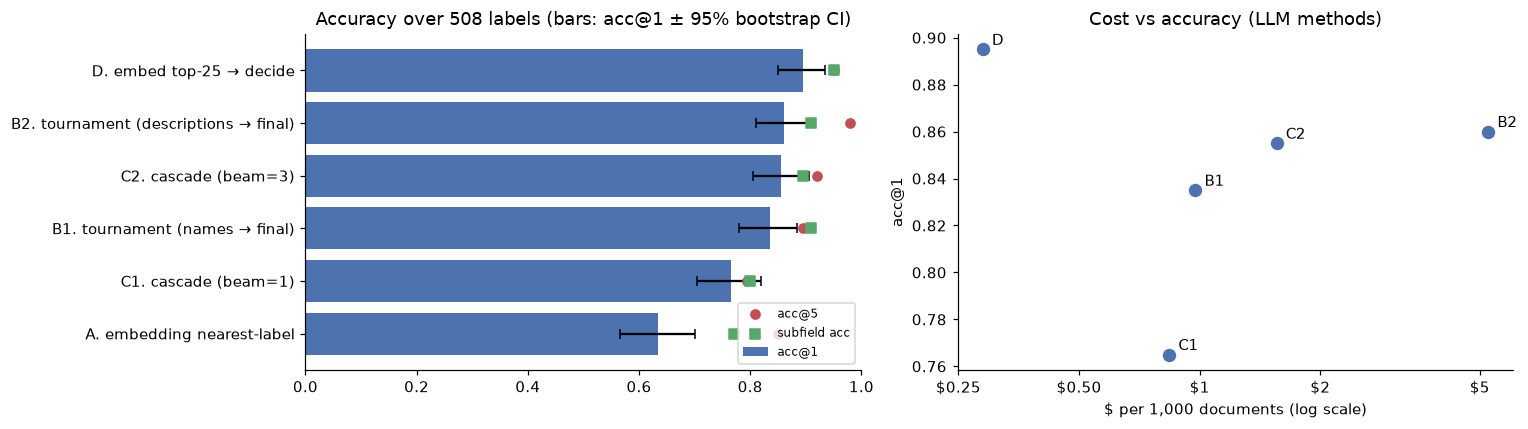

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
r = results.sort_values("acc@1")
ci = np.array([bootstrap_ci(hits_by_method[m]) for m in r.index])
axes[0].barh(r.index, r["acc@1"], xerr=[r["acc@1"] - ci[:, 0], ci[:, 1] - r["acc@1"]], color="#4C72B0", capsize=3, label="acc@1")
axes[0].scatter(r["acc@5"], r.index, color="#C44E52", zorder=3, label="acc@5")
axes[0].scatter(r["subfield acc"], r.index, color="#55A868", marker="s", zorder=3, label="subfield acc")
axes[0].set_xlim(0, 1); axes[0].set_title("Accuracy over 508 labels (bars: acc@1 ± 95% bootstrap CI)"); axes[0].legend(loc="lower right", fontsize=8)
llm = results[results["calls/doc"] > 0]
axes[1].scatter(llm["$ / 1k docs"], llm["acc@1"], s=60, color="#4C72B0")
for m, row in llm.iterrows():
    axes[1].annotate(m.split(".")[0], (row["$ / 1k docs"], row["acc@1"]), textcoords="offset points", xytext=(6, 3))
axes[1].set_xscale("log"); axes[1].minorticks_off(); axes[1].set_xticks([0.25, 0.5, 1, 2, 5], ["$0.25", "$0.50", "$1", "$2", "$5"])
axes[1].set_xlabel("$ per 1,000 documents (log scale)"); axes[1].set_ylabel("acc@1")
axes[1].set_title("Cost vs accuracy (LLM methods)")
plt.tight_layout(); plt.savefig(ROOT / "figures" / "accuracy_vs_cost.png", dpi=150, bbox_inches="tight"); plt.show()

In the right panel, shortlist then choose sits alone at the top left: the highest accuracy at the lowest cost. The other four points form a rough line from subfield first with one subfield (\$0.84, 76.5%) to the tournament with descriptions (\$5.25, 86.0%), where each extra point of accuracy costs more. The left panel shows the gap between top-1 and top-5 accuracy: the tournament with descriptions has the right topic in its top 5 for 98.0% of abstracts but first for 86.0%, so its misses are mostly close calls, while subfield first with one subfield gains little from top 5 (79.5%) because an abstract in the wrong subfield has no right answer in its list at all.

The decision model adds 26 points to the embedding model's own answer, from 127 to 179 correct, at \$0.29 per 1,000 abstracts.

### 5.2 Where the wrong answers land

A neighbouring topic in the right subfield still puts a paper on the right shelf; a topic in another field does not. The next chart sorts each method's 200 abstracts by their first choice into five outcomes: correct (dark green), wrong topic in the right subfield (light green), wrong subfield in the right field (orange), wrong field (red) and refused (grey). Each bar runs from 0 to 1, the share of the 200. Compare the orange and red parts: they are the errors that put a paper on the wrong shelf.

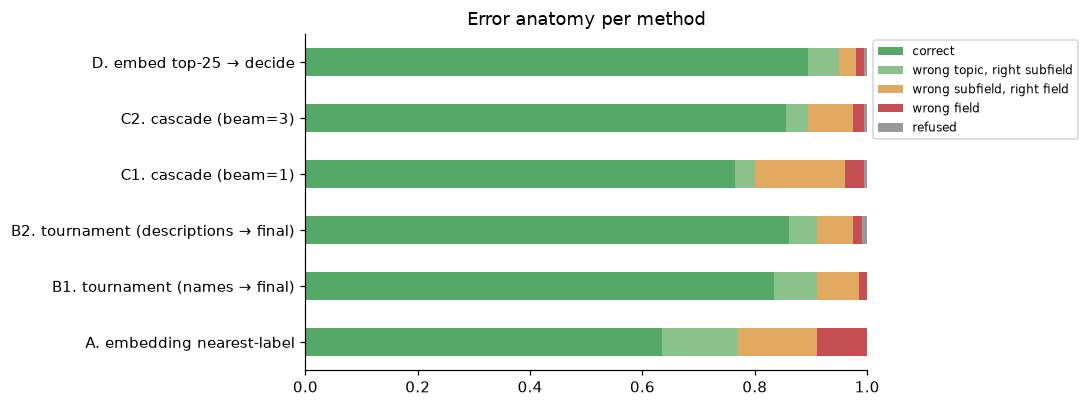

In [14]:
def outcome(p, d):
    top = p["top"][0]
    if p.get("refused"):
        return "refused"
    if top == d.topic:
        return "correct"
    if SUB_OF[top] == d.subfield:
        return "wrong topic, right subfield"
    return "wrong subfield, right field" if FIELD_OF[top] == d.field else "wrong field"


kinds = ["correct", "wrong topic, right subfield", "wrong subfield, right field", "wrong field", "refused"]
err = pd.DataFrame({m: pd.Series([outcome(p, d) for p, d in zip(P, docs.itertuples())]).value_counts(normalize=True)
                    for m, P in preds.items()}).T.reindex(columns=kinds).fillna(0)
ax = err.plot.barh(stacked=True, figsize=(10, 3.8), color=["#55A868", "#8BC28C", "#E1A95F", "#C44E52", "#999999"])
ax.set_xlim(0, 1); ax.legend(bbox_to_anchor=(1, 1), fontsize=8); ax.set_title("Error anatomy per method")
plt.tight_layout(); plt.show()

The counts behind the chart, recounted from the cached responses:

| Method | Correct | Wrong topic, right subfield | Wrong subfield, right field | Wrong field | Refused |
|---|---:|---:|---:|---:|---:|
| Similarity only | 127 | 27 | 28 | 18 | 0 |
| Tournament with names | 167 | 15 | 15 | 3 | 0 |
| Tournament with descriptions | 172 | 10 | 13 | 3 | 2 |
| Subfield first, top 1 | 153 | 7 | 32 | 7 | 1 |
| Subfield first, top 3 | 171 | 8 | 16 | 4 | 1 |
| Shortlist then choose | 179 | 11 | 6 | 3 | 1 |

Shortlist then choose has the fewest wrong-branch errors: 9 of its 20 readable mistakes left the subfield, against 39 of 46 for subfield first with one subfield. More than half of its mistakes are neighbouring topics, such as "Education, Technology, and Economics" for a paper OpenAlex files under "Economic Growth and Development".

#### Why the shortlist works and where it fails

The shortlist held the right topic for 191 abstracts, and among those the decision model chose it for 179 (93.7%). The 9 abstracts whose topic missed the shortlist make up 9 of method D's 21 misses (one of them refused). The failure is plainest on a mathematical abstract. For "The Jordan Canonical Form of a Product of Elementary S-unitary Matrices" (W3098763576), the three most similar topics were Nonlinear Dynamics and Pattern Formation, Expert finding and Q&A systems, and activated carbon and charcoal; the right topic, Matrix Theory and Algorithms, ranked 31st.

#### Why subfield first loses abstracts

Subfield first with one subfield sent 39 of the 200 abstracts to the wrong subfield at its first step and refused one more, so its second step could be right on at most 160. It was right on 153. Keeping three subfields cut the first-step misses to 15 and raised the score from 153 to 171; it was right on 22 abstracts that the one-subfield version missed and wrong on 4 it got right. The cost is the second question's length: an average of 113 topics instead of 42, and 15,565 input tokens per abstract instead of 8,396.

Of the 39 first-step misses, 14 went to Artificial Intelligence. They include the stock prediction paper from the worked example, a course recommender built with language processing (W3185225192, OpenAlex topic Recommender Systems and Techniques) and a detector of Ponzi schemes on Ethereum (W4309857254, OpenAlex topic Blockchain Technology Applications and Security). In these three, the method is machine learning, while OpenAlex files the paper by what it is applied to. Shortlist then choose filed all three correctly.

#### What the tournament pays for

The two tournaments differ only in their first round. With names alone, the right topic survived into the 16 finalists for 179 of 200 abstracts; with full descriptions, for 196 of the 198 that were answered. The final, which shows descriptions in both versions, then picked the right finalist for 167 of 179 and 172 of 196. Descriptions in round one keep the right topic in play more often, but the net gain is 5 abstracts (sign test p = 0.47) for 5.4 times the cost.

### 5.3 Can the confidence decide what to check?

Each method returns a probability for its first choice, so a catalogue could **auto-accept** confident answers and send the rest to a person. That only works if the probabilities are calibrated: of the answers given 0.9, about 9 in 10 should be right.

The **expected calibration error** (ECE) measures how far stated confidence is from observed accuracy. Answers are grouped into ten confidence bands (0 to 0.1, 0.1 to 0.2, and so on). In each band, take the gap between the average confidence and the share that were right, then average the gaps, weighting each band by its share of answers. Lower is better; 0 means confidence matches accuracy in every band. A small example with real numbers: for shortlist then choose, 173 of the 200 answers had confidence of 0.9 or more. Their average confidence was 0.991, and 162 of the 173 were right, 0.936. The gap is 0.055. That band holds 86.5% of all answers, so it adds 0.055 × 0.865 = 0.048 to the method's ECE of 0.071. The other bands, holding the remaining 27 answers, add the other 0.023.

The next cell draws two panels for the five model-based methods. The left panel, the reliability chart, groups answers into five confidence bands and plots each band's average stated confidence (horizontal) against the share that were right (vertical); it shows a point only when the band holds at least 5 abstracts. The dashed diagonal is perfect calibration, and points below it are over-confident. The legend gives each method's ECE. The right panel, the coverage chart, sorts the answers from most to least confident and plots the accuracy of the accepted set (vertical) as more of them are accepted (horizontal, the coverage). A curve that stays high as it moves right means the confidence ranks right answers above wrong ones. The first 9 abstracts are left out because their accuracy jumps between 0 and 1.

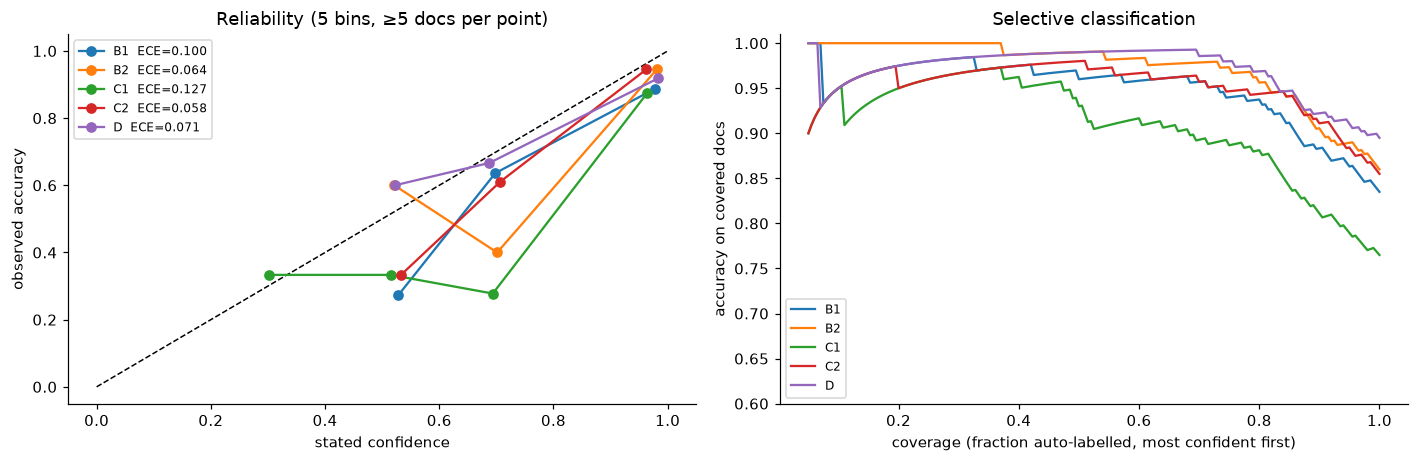

In [15]:
def ece(conf, hit, bins=10):
    edges = np.linspace(0, 1, bins + 1)
    idx = np.clip(np.digitize(conf, edges) - 1, 0, bins - 1)
    return sum(abs(conf[idx == b].mean() - hit[idx == b].mean()) * (idx == b).mean() for b in range(bins) if (idx == b).any())


show = [m for m in preds if not m.startswith("A.")]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
for m in show:
    conf = np.array([p["conf"] for p in preds[m]]); hit = hits_by_method[m]
    edges = np.linspace(0, 1, 6); idx = np.clip(np.digitize(conf, edges) - 1, 0, 4)
    xs = [conf[idx == b].mean() for b in range(5) if (idx == b).sum() >= 5]
    ys = [hit[idx == b].mean() for b in range(5) if (idx == b).sum() >= 5]
    axes[0].plot(xs, ys, "o-", label=f"{m.split('.')[0]}  ECE={ece(conf, hit):.3f}")
    order = np.argsort(-conf, kind="stable"); cum = np.cumsum(hit[order]) / np.arange(1, len(hit) + 1)
    axes[1].plot((np.arange(1, len(hit) + 1) / len(hit))[9:], cum[9:], label=m.split(".")[0])  # skip the first 9 docs (noise)
axes[0].set_xlabel("stated confidence"); axes[0].set_ylabel("observed accuracy"); axes[0].set_title("Reliability (5 bins, ≥5 docs per point)"); axes[0].legend(fontsize=8)
axes[1].set_xlabel("coverage (fraction auto-labelled, most confident first)"); axes[1].set_ylabel("accuracy on covered docs")
axes[1].set_title("Selective classification"); axes[1].legend(fontsize=8); axes[1].set_ylim(0.6, 1.01)
plt.tight_layout(); plt.show()

Every method's top band sits below the diagonal. For shortlist then choose, the 184 answers above 0.8 averaged 0.983 and 91.8% were right; for the tournament with names, 177 averaged 0.977 and 88.7%. The middle bands (0.4 to 0.6 and 0.6 to 0.8) sit mostly below the diagonal for the tournaments and subfield first, and close to it for shortlist then choose, but they hold only 5 to 18 answers per method, so their points move a lot with a few abstracts. The ECE values are 0.058 for subfield first with three subfields, 0.064 for the tournament with descriptions, 0.071 for shortlist then choose, 0.100 for the tournament with names and 0.127 for subfield first with one subfield.

In the coverage chart, shortlist then choose (purple) is at or above every other curve from about 40% coverage to the end, where it reaches its overall 89.5%; below 40% the tournament with descriptions is higher. Many answers share a confidence of exactly 1, so the left part of each curve depends on the order of the abstracts within those ties. The drop at the far right of each curve is the low-confidence answers being accepted.

The next cell turns this into a rule for the best method by top-1 accuracy, shortlist then choose: for five thresholds, the share of abstracts accepted (coverage), the accuracy on the accepted ones and the accuracy on the rest, which would go to a person.

In [16]:
best = results["acc@1"].idxmax()
conf = np.array([p["conf"] for p in preds[best]]); hit = hits_by_method[best]
pd.DataFrame([{"auto-accept if conf ≥": t, "coverage": (conf >= t).mean(), "accuracy on accepted": hit[conf >= t].mean(),
               "accuracy on rest": hit[conf < t].mean() if (conf < t).any() else np.nan}
              for t in (0.0, 0.3, 0.5, 0.7, 0.9)]).style.format("{:.2f}").set_caption(f"Thresholds for: {best}")

,auto-accept if conf ≥,coverage,accuracy on accepted,accuracy on rest
0,0.00,1.00,0.90,nan
1,0.30,0.99,0.90,0.50
2,0.50,0.98,0.90,0.67
3,0.70,0.93,0.91,0.64
4,0.90,0.86,0.94,0.63


The same table as counts, recounted from the method's cached responses in `data/decisions_cache.jsonl` (field `answers.topic.probabilities`):

| Accept if confidence is at least | Abstracts accepted | Correct among accepted | Sent to a person | Correct among those sent |
|---|---:|---|---:|---|
| 0 (accept all) | 200 | 179 (90%) | 0 | none |
| 0.3 | 198 | 178 (90%) | 2 | 1 |
| 0.5 | 197 | 177 (90%) | 3 | 2 |
| 0.7 | 186 | 170 (91%) | 14 | 9 |
| 0.9 | 173 | 162 (94%) | 27 | 17 |

At 0.9, shortlist then choose files 173 abstracts automatically and gets 162 right (93.6%, Wilson 95% interval 89% to 96%). The 27 sent to a person include 17 that were right, 9 that were wrong and the refusal. Lower thresholds barely change accuracy, because almost all answers sit at the top of the scale.

The other methods under the same 0.9 rule, recounted the same way:

| Method | ECE | Accepted at 0.9 or more | Correct among accepted | Wrong filings let through |
|---|---:|---:|---|---:|
| Tournament with names | 0.100 | 165 | 152 (92.1%) | 13 |
| Tournament with descriptions | 0.064 | 159 | 153 (96.2%) | 6 |
| Subfield first, top 1 | 0.127 | 141 | 126 (89.4%) | 15 |
| Subfield first, top 3 | 0.058 | 145 | 138 (95.2%) | 7 |
| Shortlist then choose | 0.071 | 173 | 162 (93.6%) | 11 |

Shortlist then choose files the most abstracts correctly without review, 162, against 153 for the tournament with descriptions and 138 for subfield first with three subfields. Those two let fewer wrong filings through (6 and 7 against 11), because they accept fewer abstracts. Which is better depends on what a wrong filing costs compared with a person's check.

The confidence scale is coarse. The service reports probabilities in steps of 0.01, and shortlist then choose gave probability 1 to 123 of its 200 answers. Splitting its answers by confidence shows where the reliable part is:

| Confidence of first choice | Answers | Correct |
|---|---:|---:|
| Below 0.5 (including the refusal, scored 0) | 3 | 2 |
| 0.5 to 0.69 | 11 | 7 |
| 0.7 to 0.89 | 13 | 8 |
| 0.9 to 0.98 | 31 | 22 (71%) |
| 0.99 or 1 | 142 | 140 (98.6%) |

Answers at 0.99 or 1 were almost always right (140 of 142; at exactly 1, 122 of 123). Answers between 0.9 and 0.98 were right only 71% of the time (Wilson interval 53% to 84%), far below what they state. A threshold of 0.99 would have filed 142 abstracts at 98.6%. This split was found after looking at the results, on 200 abstracts, so it needs a fresh sample before anyone relies on it.

## 6. Error analysis

The next cell lists the abstracts that shortlist then choose filed under a topic other than OpenAlex's (21 of 200), most confident first, and shows the top 10. `gold` is OpenAlex's topic and `predicted` the method's first choice. `gold in top-5` marks near misses where OpenAlex's topic was ranked 2 to 5, and `same subfield` marks first choices that are a neighbouring topic.

In [17]:
P = preds[best]
errors = pd.DataFrame([{"title": d.title[:80], "gold": d.topic, "predicted": p["top"][0], "conf": round(p["conf"], 2),
                        "gold in top-5": d.topic in p["top"], "same subfield": SUB_OF[p["top"][0]] == d.subfield}
                       for d, p in zip(docs.itertuples(), P) if p["top"][0] != d.topic])
print(f"{best}: {len(errors)} errors / {len(docs)}")
errors.sort_values("conf", ascending=False).head(10)

D. embed top-25 → decide: 21 errors / 200


,title,gold,predicted,conf,gold in top-5,same subfield
4,Robust Optimization Model with Shared Uncertain Parameters in Multi-Stage Logist,Risk and Portfolio Optimization,Supply Chain and Inventory Management,1.00,True,False
17,Implementation of Lean management Practices in Azerbaijan (on the Example of a P,Quality and Supply Management,Management and Optimization Techniques,0.99,False,False
18,CE-PBFT: A high availability consensus algorithm for large-scale consortium bloc,Blockchain Technology Applications and Security,Distributed systems and fault tolerance,0.98,False,False
16,Image Modification Using Deep Neural Cellular Automata,Generative Adversarial Networks and Image Synthesis,Cellular Automata and Applications,0.97,True,False
3,The Evolution of Luxury Consumption and Conceptualization: A Synthetic Review,Consumer Behavior in Brand Consumption and Identification,scientometrics and bibliometrics research,0.96,True,False
20,The Art of Adversity Thinking: Political Turnover and Firm Innovation,Political Influence and Corporate Strategies,Business Strategies and Innovation,0.96,True,True
14,Information Technology Role in Education and Economic Growth,Economic Growth and Development,"Education, Technology, and Economics",0.95,True,True
1,The Jordan Canonical Form of a Product of Elementary S -unitary Matrices,Matrix Theory and Algorithms,Advanced Algebra and Logic,0.94,False,True
8,Tackling the multilingual and heterogeneous documents with the pre-trained langu,Natural Language Processing Techniques,Topic Modeling,0.94,False,True
13,Research and discussion on traceability of force values for large force standard,Scientific Measurement and Uncertainty Evaluation,Sensor Technology and Measurement Systems,0.90,False,False


All ten errors shown have confidence of 0.9 or more, and so does one more not shown; all 11 would pass the auto-accept rule. The number at the left of each row is the abstract's position in the error list. The 21 misses split into three kinds, counted from the cached shortlists and responses:

- 1 refusal. Its right topic was also outside the shortlist.
- 8 readable answers where the right topic was not on the 25-topic shortlist. The decision model chose the best topic on offer, and 5 of these 8 came with confidence of 0.9 or more.
- 12 answers where the right topic was on the shortlist and the model chose another. For 11 of them OpenAlex's topic was among the model's top 5, and 6 stayed in the right subfield.

Of the 11 wrong answers that would pass the 0.9 rule, 5 are shortlist misses and 6 are choices between listed topics. The probability describes the choice among the 25 topics shown; it cannot say that the right topic was missing from them. The cases below were chosen to show each kind, plus the refusals and a correct answer that the rule sends to review.

### A shortlist miss that the other methods got right

The Jordan canonical form paper (W3098763576, number 1 in the table) defines S-unitary matrices and determines the Jordan form of a product of two of them. The embedding model ranked its topic, Matrix Theory and Algorithms, 31st, behind topics such as activated carbon and charcoal. The decision model chose Advanced Algebra and Logic, a neighbour in the same subfield, at 0.94. Both tournaments and both subfield-first versions, which never use the shortlist, filed it correctly. The pattern holds across the 9 shortlist misses: at least one other model-based method filed 8 of them correctly, and subfield first with three subfields filed 6.

### A confident choice the score counts as wrong

"Robust Optimization Model with Shared Uncertain Parameters in Multi-Stage Logistics Production and Inventory Process" (W3005017983, number 4) proposes a robust optimisation model and tests it on what the abstract calls "the multi-stage logistics production and inventory process problem". OpenAlex files it under Risk and Portfolio Optimization. Shortlist then choose had both topics on its list, in first and second place, and chose Supply Chain and Inventory Management with probability 1. It is the only wrong answer among the 123 given probability 1. Both tournaments made the same choice; subfield first with one subfield agreed with OpenAlex. The abstract supports either reading: its method is robust optimisation, its application is an inventory process.

"The Evolution of Luxury Consumption and Conceptualization: A Synthetic Review" (W4390615093, number 3) is similar. It reviews 307 papers on luxury and states that "Bibliometric analysis and content analysis were used". OpenAlex files it under Consumer Behavior in Brand Consumption and Identification; shortlist then choose chose scientometrics and bibliometrics research at 0.96. All four other model-based methods agreed with OpenAlex, and both tournaments gave its first choice only about 0.5. Here the paper's subject is luxury brands and its method is bibliometrics, and the methods split on which one defines the topic.

These cases show where top-1 accuracy against a silver label misleads. Each counts as one error, the same as a paper filed in the wrong field, although a person reading the abstract could accept the model's choice.

### Abstracts every model-based method got wrong

All five model-based methods missed 4 abstracts; all five were right on 119.

- "CE-PBFT: A high availability consensus algorithm for large-scale consortium blockchain" (W4404257738, number 18) proposes a Byzantine fault-tolerance protocol for blockchains. OpenAlex files it under Blockchain Technology Applications and Security. Every method chose Distributed systems and fault tolerance; shortlist then choose gave it 0.98, and the right topic was 27th by similarity, two places outside the shortlist. Both tournaments and subfield first with three subfields ranked OpenAlex's topic second. The paper is about both topics, and every method preferred the fault-tolerance reading.
- "SoK: Realistic adversarial attacks and defenses for intelligent network intrusion detection" (W4385973175) is the same kind of overlap. OpenAlex files it under Adversarial Robustness in Machine Learning; every model-based method chose Network Security and Intrusion Detection, and shortlist then choose gave OpenAlex's topic 0.11. Similarity only, which simply took the most similar topic, matched OpenAlex.
- "M.G. Mohanty vs. That State of Odisha" (W4386448110) discusses which Indian courts may hear commercial arbitration cases. OpenAlex files it under International Arbitration and Investment Law; every method chose Dispute Resolution and Class Actions, which shortlist then choose preferred 0.89 to 0.09.
- "Image Modification Using Deep Neural Cellular Automata" (W4309219744, number 16): OpenAlex files it under Generative Adversarial Networks and Image Synthesis; shortlist then choose chose Cellular Automata and Applications at 0.97.

In each case the model's choice names a real subject of the paper. They read as disagreements about which of two subjects is primary, which no method in this design can resolve without a person's label.

### Refusals

Five model-based runs ended in an HTTP 502 error whose message reads "OpenAI refused to answer question" and names the question. They came from 4 refused calls, because the two subfield-first versions share their first call.

| OpenAlex work | Title, shortened | Refused in | OpenAlex topic |
|---|---|---|---|
| W4281612646 | The Intermediate Guide to Jonathan Schwab | Tournament with descriptions, round 1 | Corporate Insolvency and Governance |
| W3098278328 | Challenges in the collection of convalescent plasma for COVID-19 patients | Tournament with descriptions, round 1 | Blood donation and transfusion practices |
| W3098314892 | Mechanism of "Scutellaria barbata-Hedyotis diffusa" against breast cancer | Both subfield-first versions, first step | Computational Drug Discovery Methods |
| W4226081738 | Cisco 352-001 Dumps [2022] | Shortlist then choose | Technology and Education Systems |

Two are medical papers. The other two are not research at all: the first is promotional web text about bankruptcy lawyers, the last an advertisement for exam answer files, both indexed by OpenAlex as journal articles. Every refused abstract was answered by the other methods, so a refusal depends on the question as well as the text: the bankruptcy text was refused when round one listed descriptions and answered when it listed names. The other methods filed the first three correctly; for the exam advertisement only subfield first with one subfield matched OpenAlex, at confidence 0.20. A refusal gives no label, so a filing system should send it to a person.

### A correct answer sent to review

"The Impact of Visual Stimuli on Online Shopper's Emotion: Applying S-O-R Theory in Online Fashion Retail" (W4403827652) shows the review queue doing its job. Shortlist then choose split 0.51 for Consumer Retail Behavior Studies, OpenAlex's topic, and 0.48 for Consumer Behavior and Marketing Influence. The answer is right, but at 0.51 it goes to a person, who would see two close topics. Subfield first with one subfield chose the other topic at 0.95. Of the 27 abstracts that shortlist then choose would send to review at 0.9, 17 are right answers like this one.

### What these examples cannot show

They show which topic each method returned and how sure it was, not why. The defensible-error cases are a reading of the abstract by the author of this text, not a second label from an independent person; how many of the 21 misses a person would accept has not been measured.

## 7. Spend and how to reproduce

The next cell adds up the cost recorded in every cached Decisions response.

In [18]:
spent = sum(v["usage"]["cost"] for v in decision_cache.data.values() if "usage" in v)
print(f"Total Decisions API spend recorded in cache: ${spent:.2f} over {len(decision_cache.data)} calls")

Total Decisions API spend recorded in cache: $1.76 over 1795 calls


The cache holds 1,795 Decisions responses with a recorded cost of \$1.76. The results in this notebook replay 1,595 of them (\$1.70; the 4 refusals carry no cost). The other 200 (\$0.058) come from an earlier run of shortlist then choose with a different, paid embedding model, described in the limitations; this notebook does not use them. The 708 embeddings came from a free endpoint and cost \$0. The median answered call took 1.16 seconds with 8 abstracts in flight.

| File in `data/` | What it holds |
|---|---|
| `openalex_topics.json` | The 508 OpenAlex topics with name, description, keywords, subfield and field |
| `openalex_works.jsonl` | The 600 sampled works: title, year, primary topic and score, abstract |
| `decisions_cache.jsonl` | Every Decisions response, keyed by a hash of the full request: probabilities, usage, cost, model version, latency, or a refusal |
| `embeddings_cache.npz` | The 708 embedding vectors, keyed by a hash of model name and text |
| `PROTOCOL.md` | Run history: dates, settings, the option-limit probe, refusals, the earlier shortlist run and spend |

To reproduce, install the dependencies (`pip install -r ../../requirements.txt`) and run `jupyter nbconvert --to notebook --execute --inplace 01_decisions_api_500_label_classification.ipynb` from this folder. Every call replays from the cache without an API key. A request missing from the cache needs `OPENROUTER_API_KEY` and is sent to OpenRouter. `N_DOCS` (200) in the setup cell sets the sample size; re-running from an empty cache would make 1,595 Decisions calls, about \$1.70.

## 8. What the evidence supports

- To file documents against a long label list with this decision model, shortlist by text similarity and ask one question over the shortlist: 179 of 200 correct, \$0.29 per 1,000 documents, under a second each. Subfield first with three subfields or a tournament with descriptions may be as accurate, but cost 5 and 18 times as much and take three times as long.
- Do not narrow with a single first step that cannot be revised. Choosing one subfield first lost 39 of 200 abstracts before the topic question was asked.
- Check the shortlist, not just the model. 9 abstracts were lost because the right topic was not among the 25, and the model gave 5 of them confidence of 0.9 or more. A better embedding model or a longer shortlist (98% at 50 topics) is the cheapest place to look for gains.
- Use the confidence to sort work, not as a literal probability. Accepting 0.9 or more filed 86.5% of abstracts at 93.6% accuracy. Answers at 0.99 or 1 were right 140 of 142 times; those between 0.90 and 0.98 behaved more like 70% than 95%.
- Treat a refusal as "send to a person". Refusals were rare (5 of 1,000 runs) and hit two medical papers and two advertisements.

The uncertainty that most needs another experiment is how accurate these methods are on papers the model cannot have seen, scored against labels a person has checked.

## 9. Limitations

- The data predates the repository's fresh-data rule. The papers were published 2020 to 2024 and their OpenAlex topics were public before the model was released, so the accuracy is an upper bound for new papers.
- The right answers are silver labels from OpenAlex's own classifier, kept only at a score of 0.9 or more. Which version of that classifier labelled them is not recorded. Several counted errors are defensible readings (section 6), and no person has labelled the 200 abstracts.
- 200 abstracts give 95% intervals about 5 points either side of each accuracy. The three best model-based methods are within that range of each other.
- One sample, one tournament split, one shortlist length (25) and one embedding model, the weakest part of the best method.
- The 255-option limit that shapes every design has no saved evidence (section 3), so a single question over all 508 topics was not compared.
- The cache also holds 200 responses from an earlier run of shortlist then choose with a paid embedding model (OpenAI's text-embedding-3-small, according to the notebook's earlier notes). Matched to the same abstracts by request hash, its shortlist held the right topic for 197 and it filed 182 correctly (91.0%). Its embeddings were not saved, so it cannot be replayed and is not in the results. Run history is in `data/PROTOCOL.md`.
- The methods and measures were not fixed in a written plan before the results were seen. The confidence split at 0.99 in section 5.3 was found after looking at the results.
- Only one decision model was tested, at one version, through one provider.

## 10. Future work and further reading

Follow-up experiments that the results and limitations above point to, and sources for the methods this notebook uses. Links checked on 28 October 2026.

### Future work
- Score against labels a person has checked. Have two people label the 200 abstracts and recount every method. Motivated by the defensible errors in section 6 and the 4 abstracts every method filed under the same non-OpenAlex topic.
- Separate shortlist misses from choice errors. Rerun shortlist then choose with 50 and 100 topics and with a larger open-weight embedding model, and report how many of its 21 misses each change fixes. Motivated by the 9 misses whose topic never reached the shortlist.
- Test a single question over all topics. Send one 508-option question, save the service's reply whether it answers or rejects, and compare accuracy and cost with the shortlist. Motivated by the unsaved rejection behind the 255-option limit.
- Test the confidence rule at scale and on new papers. Classify 2,000 abstracts published after the model's release, fit the threshold on half and check coverage and accuracy on the other half, including whether answers at 0.99 or 1 stay near 98.6% correct. Motivated by the 31 answers between 0.90 and 0.98 that were right 71% of the time.
- Scale to the full OpenAlex tree of 4,516 topics in 26 fields, where a shortlist keeps 25 of 4,516 and a cascade gains a level, so the two designs are tested where they differ most.

### Further reading
- [Decisions](https://developers.openai.com/api/docs/guides/decisions) (OpenAI API guide). The vendor's description of the model tested here: typed questions over fixed options, answered with probabilities instead of text.
- [Submit a Decisions request](https://openrouter.ai/docs/api/api-reference/alphadecisions/submit-a-decisions-request) (OpenRouter API reference). The endpoint and request body (evidence and questions) that the notebook sends.
- [Topics](https://help.openalex.org/data/topics/) (OpenAlex help). How OpenAlex builds its 4,516 topics and assigns them to works, and so what the silver labels here mean.
- [On Calibration of Modern Neural Networks](https://arxiv.org/abs/1706.04599) (Guo et al., 2017). Defines expected calibration error and temperature scaling, the measure used in section 5.3 and the usual fix for over-confident probabilities.
- [Selective Classification for Deep Neural Networks](https://arxiv.org/abs/1705.08500) (Geifman and El-Yaniv, 2017). The trade-off between coverage and accuracy behind the auto-accept threshold.
- [In-Context Learning for Extreme Multi-Label Classification](https://arxiv.org/abs/2401.12178) (D'Oosterlinck et al., 2024). A pipeline that infers, retrieves and ranks over thousands of labels, close to shortlist then choose.